# Relações entre participação, perfil e desempenho

**Área de análise:** Pará (PA)  
**Referência territorial:** município da escola (ESC)  
**Período:** 1998–2025, conforme disponibilidade de cada fonte e questão.  
**Fontes:** `painel`, `faixa` e `grupo`.

**OBJETIVO**

Analisa se as mudanças na participação e na composição dos participantes estão associadas ao desempenho municipal, além de examinar a relação entre diversidade etária, dispersão das notas e desigualdade entre redes. A unidade de análise é o município-ano, com recortes por disciplina quando aplicável.

---
<div style="background-color: #f5f0dc; padding: 12px; border-radius: 6px;">
    
> **Nota Metodológica**\
As análises utilizam correlações de Pearson e Spearman. Pearson avalia associação linear; Spearman avalia associação monotônica baseada em ordenação. Os coeficientes descrevem associações entre municípios e não demonstram causalidade nem relações individuais entre estudantes.
</div>

### Principais achados
<div style="background-color: #DBEAFE; padding: 12px; border-radius: 6px;">
    
> **A expansão da participação não se converteu em ganho generalizado**  
> Em Matemática, a correlação entre crescimento da participação e variação do desempenho foi negativa (Spearman = **−0,332**), e a mediana da variação da média municipal foi de **−3,4 pontos**.

> **Associação persistente com a participação da rede pública**  
> Em 2025, os coeficientes de Spearman entre a proporção de participantes da rede pública e o desempenho municipal variaram de **−0,482 a −0,580** nas cinco disciplinas. A associação permaneceu negativa ao longo de 2009–2025.

> **Menor dispersão nas provas objetivas entre municípios de maior diversidade etária**  
> No grupo de maior diversidade (G5), os valores medianos de desvio-padrão e IQR foram inferiores aos do G1 nas quatro provas objetivas. Em Matemática, por exemplo, o desvio-padrão mediano foi **77,74 no G5**, ante **83,62 no G1**. O padrão não se reproduziu de forma consistente em Redação.
 </div>

---

## Configuração e carga

In [31]:
from _setup2 import *

UF_PROCESSAMENTO = "PA"
TIPO_REFERENCIA = "ESC"

out = read_allfiles2(UF_PROCESSAMENTO, TIPO_REFERENCIA)

painel = out["painel"]["data"].copy()
faixa = out["faixa"]["data"].copy()
grupo = out["grupo"]["data"].copy()

desempenho_e7 = eda2.preparar_painel_eixo7(painel, TIPO_REFERENCIA)

print("=" * 46)
print(f"UF: {UF_PROCESSAMENTO}  | Período :{painel['ano'].min()}–{painel['ano'].max()}| Referência: {TIPO_REFERENCIA} ")
print("=" * 46)
print(f"painel  : {painel.shape[0]:,} x {painel.shape[1]}".replace(",", "."))
print(f"faixa   : {faixa.shape[0]:,} x {faixa.shape[1]}".replace(",", "."))
print(f"grupo   : {grupo.shape[0]:,} x {grupo.shape[1]}".replace(",", "."))
print("=" * 46)

UF: PA  | Período :1998–2025| Referência: ESC 
painel  : 3.625 x 82
faixa   : 38.335 x 7
grupo   : 186.449 x 16


## 1. Crescimento da participação e mudança no desempenho

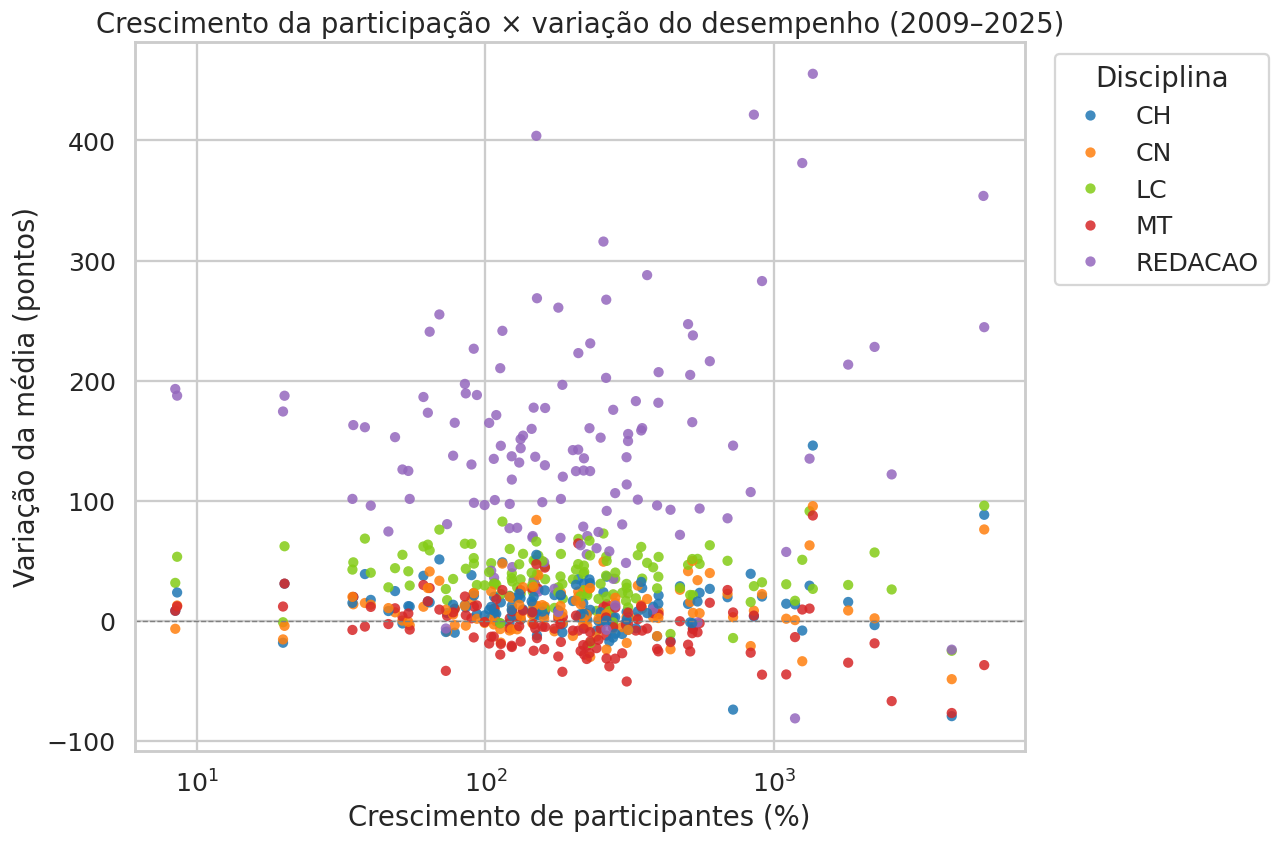

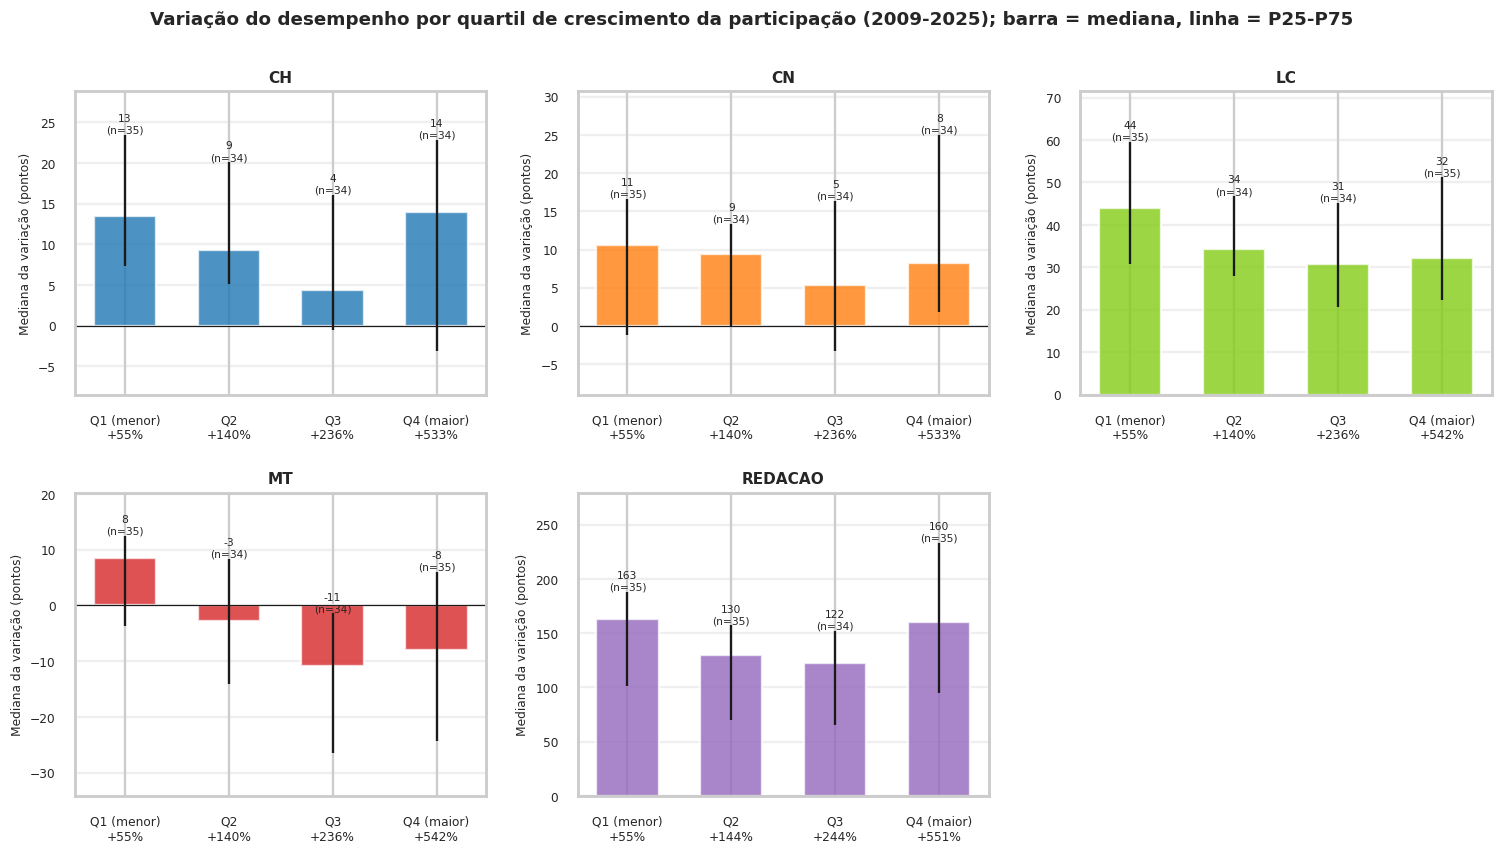

In [47]:
r01_municipal, r01_correlacoes = eda2.analisar_r01_crescimento_participacao_desempenho(
    painel, desempenho_e7, ano_inicial=2009, ano_final=2025, referencia=TIPO_REFERENCIA)



DISC5 = ["CH", "CN", "LC", "MT", "REDACAO"]
CORES = {"CH": "#1f77b4", "CN": "#ff7f0e", "LC": "#84cc16", "MT": "#d62728", "REDACAO": "#9467bd"}

fig, ax = plt.subplots(figsize=(12, 8))

sns.scatterplot(data=r01_municipal,
                x="crescimento_participacao_pct",
                y="variacao_media_pontos",
                hue="disciplina",
                hue_order=DISC5,
                palette=CORES,
                s=45,
                alpha=0.85,
                edgecolor="none",
                ax=ax)

ax.axhline(0, color="grey", linewidth=0.9, linestyle="--")
ax.axvline(0, color="grey", linewidth=0.9, linestyle="--")
ax.set(
    title="Crescimento da participação × variação do desempenho (2009–2025)",
    xlabel="Crescimento de participantes (%)",
    ylabel="Variação da média (pontos)")
#ax.set_xlim(-50, 1000)
ax.set_xscale("log")
ax.legend(title="Disciplina", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


r = (r01_municipal[r01_municipal.disciplina.isin(DISC5)]
     .dropna(subset=["variacao_media_pontos", "crescimento_participacao_pct"]).copy())
r["razao_part"] = 1 + r.crescimento_participacao_pct / 100       # participação final / inicial
ai, af = int(r.ano_inicial.iloc[0]), int(r.ano_final.iloc[0])
corr = r01_correlacoes.set_index("disciplina")
r["quartil"] = r.groupby("disciplina").crescimento_participacao_pct.transform(
    lambda v: pd.qcut(v, 4, labels=["Q1 (menor)", "Q2", "Q3", "Q4 (maior)"]))
res = (r.groupby(["disciplina", "quartil"], observed=True).variacao_media_pontos
         .agg(mediana="median", q25=lambda v: v.quantile(.25),
              q75=lambda v: v.quantile(.75), n="count").reset_index())
med_cresc = (r.groupby(["disciplina", "quartil"], observed=True)
               .crescimento_participacao_pct.median())

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
rotulos = ["Q1 (menor)", "Q2", "Q3", "Q4 (maior)"]
for ax, disc in zip(axes.flat, DISC5):
    s = res[res.disciplina == disc].set_index("quartil").loc[rotulos]
    x = np.arange(len(s))
    ax.bar(x, s.mediana, color=CORES[disc], alpha=.8, width=.6)
    ax.vlines(x, s.q25, s.q75, color="k", lw=1.5)
    ax.axhline(0, color="k", lw=.8)
    for xi, (md, n) in enumerate(zip(s.mediana, s.n)):
        ax.text(xi, s.q75.iloc[xi], f"{md:.0f}\n(n={n})", ha="center", va="bottom", fontsize=7)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{q}\n+{med_cresc[(disc, q)]:.0f}%" for q in rotulos], fontsize=7)
    ax.set_title(disc, fontsize=10, fontweight="bold")
    ax.set_ylabel("Mediana da variação (pontos)", fontsize=8)
    ax.margins(y=0.2); ax.grid(axis="y", alpha=.3); ax.tick_params(labelsize=8)

axes.flat[-1].axis("off")
fig.suptitle(f"Variação do desempenho por quartil de crescimento da participação ({ai}-{af}); "
             f"barra = mediana, linha = P25-P75", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

### Comentários

A comparação foi realizada entre 2009 e 2025, considerando municípios pareados e cinco disciplinas: Ciências Humanas (CH), Ciências da Natureza (CN), Linguagens e Códigos (LC), Matemática (MT) e Redação. Para cada município, foram calculados o crescimento percentual da participação no ENEM e a variação da média municipal, expressa em pontos.

Os resultados das correlações não indicam uma associação positiva generalizada entre a expansão da participação e o crescimento do desempenho. Ciências Humanas, Ciências da Natureza e Linguagens apresentam correlações fracas ou próximas de zero. Em Redação, a correlação de Pearson é positiva, mas fraca, enquanto a de Spearman é praticamente nula. Matemática apresenta as associações negativas mais expressivas, com coeficientes de −0,317 em Pearson e −0,332 em Spearman.

| Disciplina | Municípios na correlação | Pearson | Spearman | Mediana da variação da média (pontos) |
|---|---:|---:|---:|---:|
| CH | 137 | 0,043 | −0,158 | 9,5 |
| CN | 137 | 0,118 | 0,017 | 7,7 |
| LC | 138 | 0,006 | −0,189 | 35,1 |
| MT | 138 | −0,317 | −0,332 | −3,4 |
| Redação | 139 | 0,175 | −0,001 | 136,6 |

A mediana da variação das médias municipais foi positiva em Ciências Humanas, Ciências da Natureza, Linguagens e Redação. Em Matemática, foi ligeiramente negativa. Portanto, a evolução do desempenho não acompanhou de maneira uniforme o crescimento da participação, e a magnitude dessa expansão não explica, por si só, a variação das médias municipais.

**Comparação por quartis de crescimento da participação**

Para aprofundar essa análise, os municípios foram agrupados em quatro quartis conforme o crescimento percentual da participação entre 2009 e 2025, do menor para o maior crescimento. Comparar as medianas da variação das médias municipais mostra como o desempenho variou entre esses grupos.

* Em Ciências Humanas, as medianas foram de 13,42 pontos no primeiro quartil, 9,34 no segundo, 4,34 no terceiro e 13,93 no quarto. Não há sequência monotônica: o grupo de maior expansão superou os intermediários e ficou próximo ao primeiro.

* Em Ciências da Natureza, as medianas caíram de 10,65 para 9,39 e 5,38 pontos nos três primeiros quartis, subindo para 8,29 no quarto, sem relação proporcional com o crescimento da participação.

* Em Linguagens, todas as medianas foram positivas, caindo de 43,88 pontos no primeiro quartil para 34,40 e 30,85 nos intermediários, e chegando a 32,14 no quarto.

* Matemática teve o padrão mais desfavorável, com mediana de 8,44 pontos no primeiro quartil, passando a −2,72 no segundo, −10,78 no terceiro e −8,07 no quarto, apesar da recuperação no último grupo.

* Na Redação, as medianas ficaram positivas e acima das demais áreas: 163,01 pontos no primeiro quartil, 129,57 no segundo, 122,35 no terceiro e 160,46 no quarto, repetindo o comportamento não monotônico entre extremos.

Em conjunto, a relação entre expansão da participação e evolução do desempenho varia conforme a disciplina. Em Ciências Humanas, Ciências da Natureza e Redação, o maior crescimento da participação não implicou as menores variações medianas; em Linguagens, os ganhos diminuíram, mas seguiram positivos; em Matemática, a associação negativa foi mais consistente, com medianas abaixo de zero nos três últimos quartis.

Os dados não sustentam que maior expansão da participação leve em geral a maior ganho de desempenho, nem que o aumento da participação cause queda nas médias em Matemática, evidenciando padrões não monotônicos sobretudo em Ciências Humanas e Redação. É necessário considerar também que crescimentos percentuais elevados podem ocorrer em municípios com bases iniciais pequenas. Por essa razão, os resultados dos grupos extremos devem ser interpretados com cautela. A análise é descritiva e não permite estabelecer relações causais entre a expansão da participação e a evolução do desempenho.

## 2. Participação da rede pública e desempenho municipal

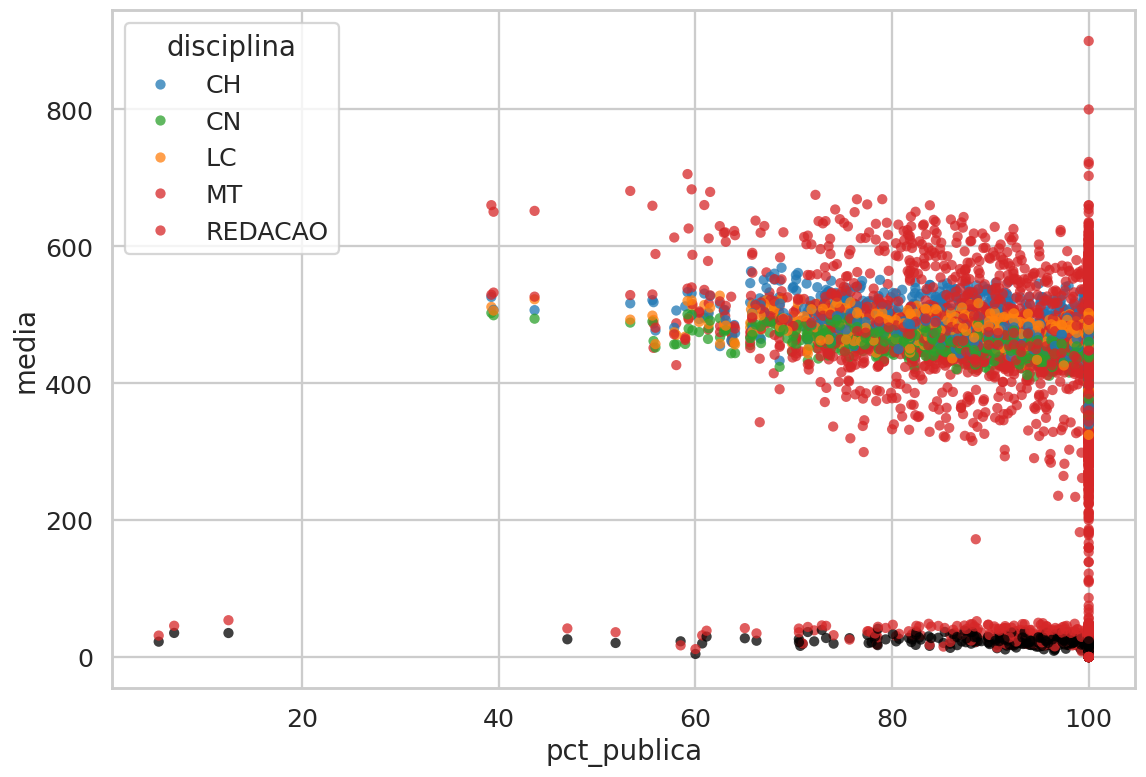

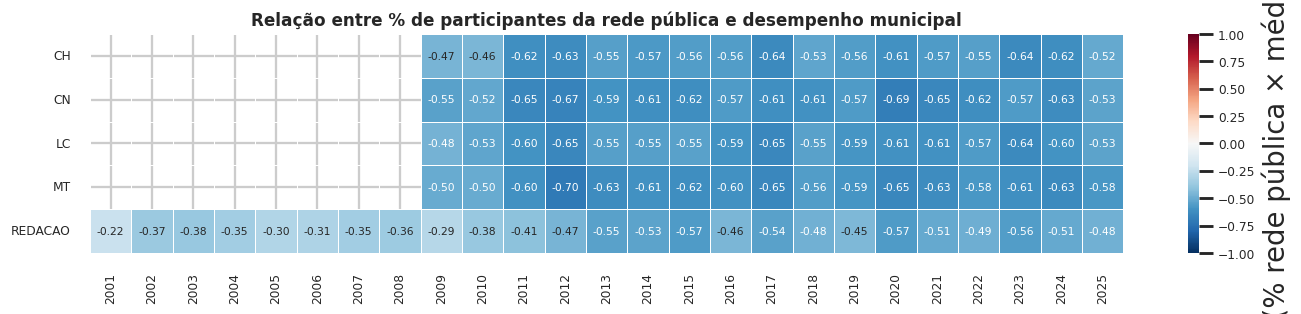

In [54]:
r02_municipal, r02_correlacoes = eda2.analisar_r02_rede_publica_desempenho(painel, desempenho_e7, TIPO_REFERENCIA)

fig, ax = plt.subplots(figsize=(12, 8))

sns.scatterplot(data=r02_municipal,
                x="pct_publica",
                y="media",
                hue="disciplina",
                hue_order=DISC5,
                palette=CORES,
                s=45,
                alpha=0.75,
                edgecolor="none",
                ax=ax)


DISC5 = ["CH", "CN", "LC", "MT", "REDACAO"]
CORES = {"CH": "#1f77b4", "CN": "#2ca02c", "LC": "#ff7f0e", "MT": "#d62728", "REDACAO": "#d62728"}

r = (r02_municipal[r02_municipal.disciplina.isin(DISC5)]
     .dropna(subset=["pct_publica", "media"]).copy())
if r.pct_publica.max() <= 1.0:                 # converte proporção (0-1) para %
    r["pct_publica"] = r.pct_publica * 100
c = r02_correlacoes[r02_correlacoes.disciplina.isin(DISC5)].copy()
ANO_FIM = int(r.ano.max())

h = c.pivot(index="disciplina", columns="ano", values="spearman").loc[DISC5]

fig, ax = plt.subplots(figsize=(13, 3.2))
sns.heatmap(h, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot_kws={"fontsize": 7}, linewidths=.5, linecolor="white",
            cbar_kws={"label": "Spearman (% rede pública × média municipal)"}, ax=ax)
ax.set_title("Relação entre % de participantes da rede pública e desempenho municipal",
             fontsize=11, fontweight="bold")
ax.set_xlabel(""); ax.set_ylabel("")
ax.tick_params(labelsize=8); ax.figure.axes[-1].tick_params(labelsize=8)
plt.tight_layout(); plt.show()



### Comentário
A análise investiga a relação entre a proporção de participantes provenientes da rede pública e a média municipal do ENEM no Pará. Para isso, foram considerados os municípios com informações disponíveis em cada ano, distinguindo as cinco disciplinas do Novo ENEM: Ciências Humanas (CH), Ciências da Natureza (CN), Linguagens e Códigos (LC), Matemática (MT) e Redação.

Os coeficientes de correlação de Spearman revelam uma associação negativa entre a participação da rede pública e a média municipal em todas as disciplinas, ao longo de todo o período de 2009 a 2025. Esse comportamento indica que municípios com maior proporção de participantes da rede pública tendem a apresentar médias municipais menores. A intensidade dessa associação, entretanto, varia conforme a disciplina e o ano.

| Disciplina                | Municípios (2025) | Pearson | Spearman |
| ------------------------- | ----------------- | ------- | -------- |
| Ciências Humanas (CH)     | 142               | −0,556  | −0,515   |
| Ciências da Natureza (CN) | 142               | −0,626  | −0,532   |
| Linguagens e Códigos (LC) | 142               | −0,609  | −0,533   |
| Matemática (MT)           | 142               | −0,617  | −0,580   |
| Redação                   | 142               | −0,494  | −0,482   |

Em 2025, as correlações de Spearman foram de −0,515 em Ciências Humanas, −0,532 em Ciências da Natureza, −0,533 em Linguagens, −0,580 em Matemática e −0,482 em Redação. Matemática apresentou a associação negativa mais elevada, enquanto Redação registrou a menor magnitude. Os coeficientes de Pearson também foram negativos nas cinco disciplinas, reforçando a direção da relação observada.

A persistência dessa associação ao longo do período é um aspecto importante dos resultados. Entre 2009 e 2025, os coeficientes de Spearman permaneceram negativos em todas as disciplinas, com magnitudes que variaram de −0,458 a −0,638 em Ciências Humanas, de −0,519 a −0,695 em Ciências da Natureza, de −0,476 a −0,653 em Linguagens, de −0,501 a −0,704 em Matemática e de −0,289 a −0,568 em Redação. Portanto, a relação não se restringe a um ano específico, embora sua intensidade apresente oscilações ao longo da série.

Também se observa que a associação tende a ser menos intensa na Redação do que nas provas objetivas. Esse comportamento aparece tanto nos coeficientes de Pearson quanto nos de Spearman e se mantém na maior parte do período analisado.

Os resultados indicam uma associação negativa persistente entre a participação relativa da rede pública e o desempenho médio municipal. Municípios nos quais a rede pública representa uma parcela maior dos participantes tendem a apresentar médias menores, com associação mais expressiva em Matemática e, em geral, menor em Redação. Esse padrão descreve uma relação entre características agregadas dos municípios e não permite concluir que a participação na rede pública, isoladamente, determine o desempenho dos estudantes.

É importante considerar que a correlação é calculada entre municípios e não representa uma comparação individual entre estudantes da rede pública e privada. As diferenças observadas podem estar relacionadas a outros aspectos da composição social, territorial e escolar dos municípios, que não são isolados por esse procedimento. Assim, os coeficientes devem ser interpretados como indicadores de associação territorial, e não como estimativas de efeito da dependência administrativa sobre as notas.


## 3. Composição por sexo e desempenho municipal

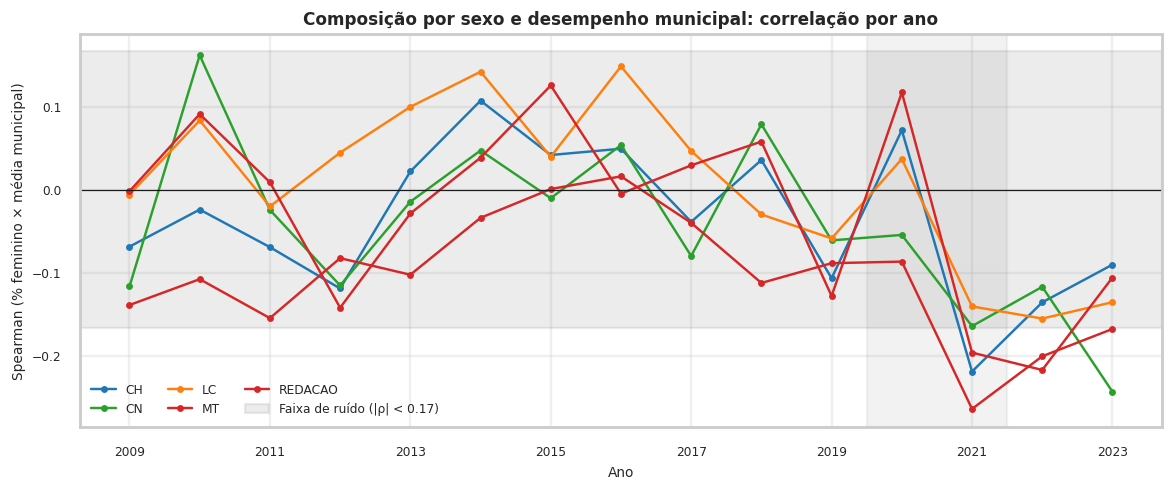

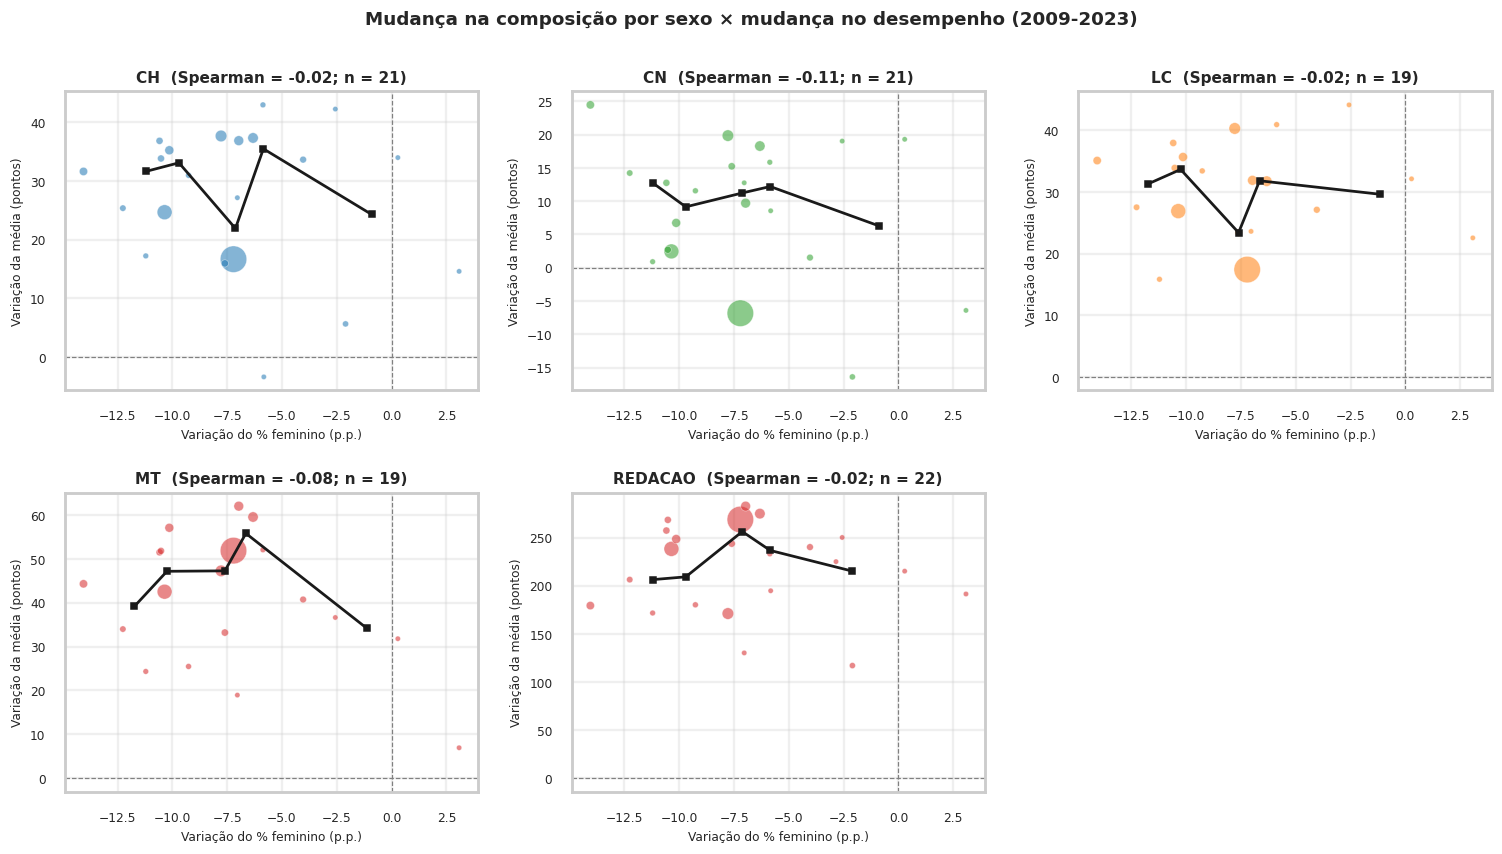

In [37]:
r03_municipal, r03_correlacoes = eda2.analisar_r03_sexo_desempenho(painel, desempenho_e7, TIPO_REFERENCIA, ano_final=2023)


c = r03_correlacoes[(r03_correlacoes.ano >= 2009) & r03_correlacoes.disciplina.isin(DISC5)]

fig, ax = plt.subplots(figsize=(11, 4.8))
for disc in DISC5:
    s = c[c.disciplina == disc].sort_values("ano")
    ax.plot(s.ano, s.spearman, marker="o", ms=3.5, lw=1.6, color=CORES[disc], label=disc)
n = int(c.n_municipios.median()); lim = 1.96 / np.sqrt(n - 3)
ax.axhspan(-lim, lim, color="gray", alpha=.15, label=f"Faixa de ruído (|ρ| < {lim:.2f})")
ax.axhline(0, color="k", lw=.8)
ax.axvspan(2019.5, 2021.5, color="gray", alpha=.10)
ax.set_xticks(range(2009, 2024, 2))
ax.set_xlabel("Ano", fontsize=9); ax.set_ylabel("Spearman (% feminino × média municipal)", fontsize=9)
ax.set_title("Composição por sexo e desempenho municipal: correlação por ano",
             fontsize=11, fontweight="bold")
ax.legend(frameon=False, fontsize=8, ncol=3); ax.grid(alpha=.3); ax.tick_params(labelsize=8)
plt.tight_layout(); plt.show()


ANO_I, ANO_F, MIN_N = 2009, 2023, 200     # MIN_N: notas válidas mínimas nos dois anos

d = r03_municipal[r03_municipal.disciplina.isin(DISC5)]
chave = ["CO_MUNICIPIO_TERRITORIO", "disciplina"]
a = d[d.ano == ANO_I].set_index(chave)
b = d[d.ano == ANO_F].set_index(chave)
#j = a.join(b, lsuffix="_i", rsuffix="_f", how="inner").reset_index()

j = a.merge(b, left_index=True, right_index=True, how="inner",
            suffixes=("_i", "_f")).reset_index()
j = j[(j.n_validos_i >= MIN_N) & (j.n_validos_f >= MIN_N)].copy()
j["d_fem"]   = j.pct_feminino_f - j.pct_feminino_i
j["d_media"] = j.media_geral_f - j.media_geral_i




fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, disc in zip(axes.flat, DISC5):
    s = j[j.disciplina == disc]
    ax.scatter(s.d_fem, s.d_media, s=np.clip(s.n_validos_f / s.n_validos_f.max() * 300, 12, 300),
               color=CORES[disc], alpha=.55, edgecolor="white", lw=.4)
    q = pd.qcut(s.d_fem, 5, duplicates="drop")
    m = s.groupby(q, observed=True)[["d_fem", "d_media"]].median()
    ax.plot(m.d_fem, m.d_media, color="k", lw=1.8, marker="s", ms=4)
    ax.axhline(0, color="gray", ls="--", lw=.8); ax.axvline(0, color="gray", ls="--", lw=.8)
    rho = s.d_fem.corr(s.d_media, method="spearman")
    ax.set_title(f"{disc}  (Spearman = {rho:.2f}; n = {len(s)})", fontsize=10, fontweight="bold")
    ax.set_xlabel("Variação do % feminino (p.p.)", fontsize=8)
    ax.set_ylabel("Variação da média (pontos)", fontsize=8)
    ax.grid(alpha=.3); ax.tick_params(labelsize=8)
axes.flat[-1].axis("off")
fig.suptitle(f"Mudança na composição por sexo × mudança no desempenho ({ANO_I}-{ANO_F})",
             fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()


### Comentários
A relação entre o perfil demográfico dos participantes e o desempenho médio dos municípios paraenses no ENEM foi investigada por meio de duas abordagens complementares. A primeira avalia a associação ano a ano entre o percentual de participantes do sexo feminino e a nota média municipal. A segunda analisa a relação entre as variações acumuladas dessas duas variáveis ao longo do período de 2009 a 2023. Como as médias municipais englobam o conjunto total de estudantes, os resultados refletem padrões agregados das localidades, não sendo aplicáveis a diferenças individuais entre os sexos nem suficientes para inferir relações de causalidade.

Na avaliação realizada ano a ano, cuja cobertura territorial permaneceu estável entre 138 e 143 municípios por disciplina, os coeficientes de correlação observados entre 2009 e 2020 apresentam baixa magnitude e alternam entre sinais positivos e negativos. A maior parte desses valores situa-se dentro da faixa de referência aproximada ($\vert{}\rho\vert{} < 0,17$), estimada a partir do número mediano de 141 municípios por ano, o que descarta uma associação monotônica persistente nesse intervalo. A partir de 2021, ocorre uma inflexão parcial, com o surgimento de correlações negativas simultâneas nas cinco áreas avaliadas. Nesse triênio final, os destaques negativos ocorreram em Matemática (−0,264) em 2021, Redação (−0,217) e Matemática (−0,201) em 2022, e Ciências da Natureza (−0,243) em 2023. Contudo, esse comportamento recente não configura uma tendência estrutural de longo prazo, e a faixa de referência adotada serve apenas como parâmetro descritivo, sem substituir testes formais de significância estatística.

Para verificar a relação entre as mudanças acumuladas entre 2009 e 2023, aplicou-se um filtro de consistência que restringiu a amostra aos municípios com ao menos 200 notas válidas em ambos os anos, resultando em um recorte de 19 a 22 localidades por área. Nesse conjunto, verificou-se uma retração mediana na participação feminina em todas as disciplinas, acompanhada por uma elevação generalizada nas médias municipais, conforme detalhado na tabela a seguir.

| **Disciplina** | **Municípios** | **Spearman** | **Pearson** | **Variação mediana do % feminino (p.p.)** | **Variação mediana da média** |
| -------------- | -------------- | ------------ | ----------- | ----------------------------------------- | ----------------------------- |
| CH             | 21             | −0,022       | −0,164      | −7,21                                     | +31,62                        |
| CN             | 21             | −0,112       | −0,284      | −7,21                                     | +11,55                        |
| LC             | 19             | −0,018       | −0,015      | −7,61                                     | +31,89                        |
| MT             | 19             | −0,084       | −0,370      | −7,61                                     | +42,51                        |
| Redação        | 22             | −0,020       | −0,090      | −7,13                                     | +229,06                       |

Os coeficientes de Spearman entre as variações das duas variáveis aproximam-se de zero em todas as disciplinas, evidenciando a ausência de uma ordenação monotônica entre a queda do percentual feminino e o avanço nas notas. Por sua vez, os coeficientes de Pearson também são negativos, mas exibem magnitudes mais elevadas em Matemática (−0,370) e Ciências da Natureza (−0,284). A discrepância entre os dois indicadores demonstra que eventuais associações lineares nessas áreas não se traduzem em um alinhamento consistente dos municípios, exigindo cautela na interpretação devido ao tamanho reduzido da amostra.

A estratificação dos municípios em quintis, ordenada pela variação da participação feminina, corrobora os achados das correlações ao não revelar progressão crescente ou decrescente nas medianas de desempenho. As oscilações ocorrem de forma errática entre os grupos em todas as áreas: Ciências Humanas varia entre 21,89 e 35,48 pontos; Linguagens e Códigos, entre 23,40 e 33,66 pontos; Ciências da Natureza, entre 6,31 e 12,75 pontos; e Redação, entre 206,29 e 256,23 pontos. Em Matemática, embora os ganhos se concentrem nos extratos intermediários e no quarto quintil, há retração no quinto quintil, confirmando que a intensidade da mudança demográfica não organiza sistematicamente a evolução das notas.

As duas abordagens apresentam resultados convergentes quanto à ausência de uma associação consistente entre a composição por sexo e o desempenho médio municipal. Na série anual, as correlações são geralmente pequenas e alternam de sinal, embora apresentem valores negativos simultâneos nas cinco disciplinas em 2021 e 2022, permanecendo negativas em 2023. Na comparação longitudinal, as correlações entre as mudanças das variáveis são próximas de zero, especialmente quando consideradas pelo coeficiente de Spearman. A redução mediana do percentual feminino entre 2009 e 2023 ocorreu simultaneamente ao aumento das médias municipais nas cinco disciplinas. Entretanto a ausência de um padrão consistente nas correlações e na distribuição por quintis indica que, nesta análise agregada, a mudança na composição por sexo não explica de forma sistemática as diferenças nos ganhos de desempenho entre os municípios paraenses.



## 4. Diversidade etária e dispersão do desempenho

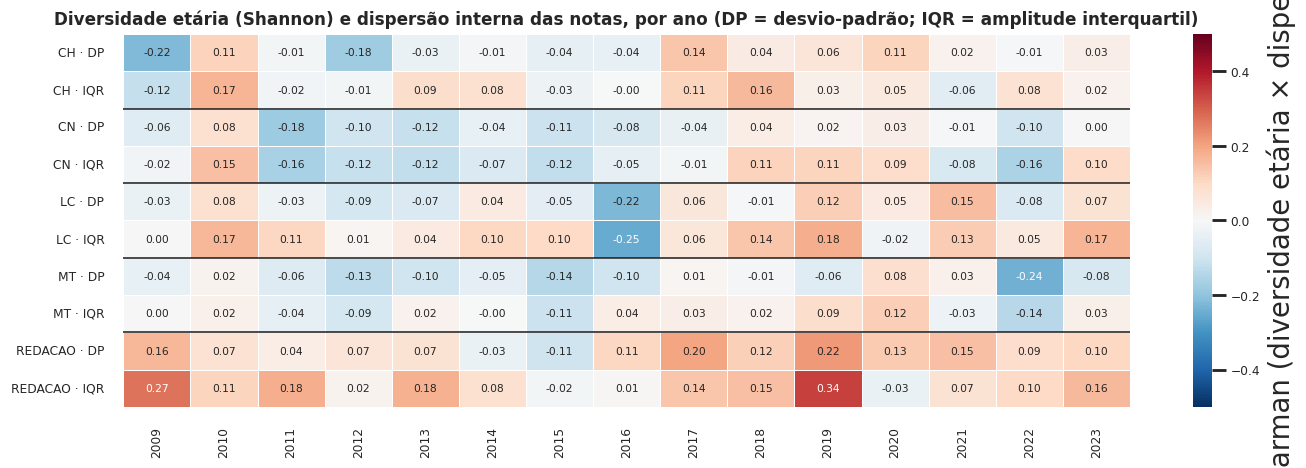

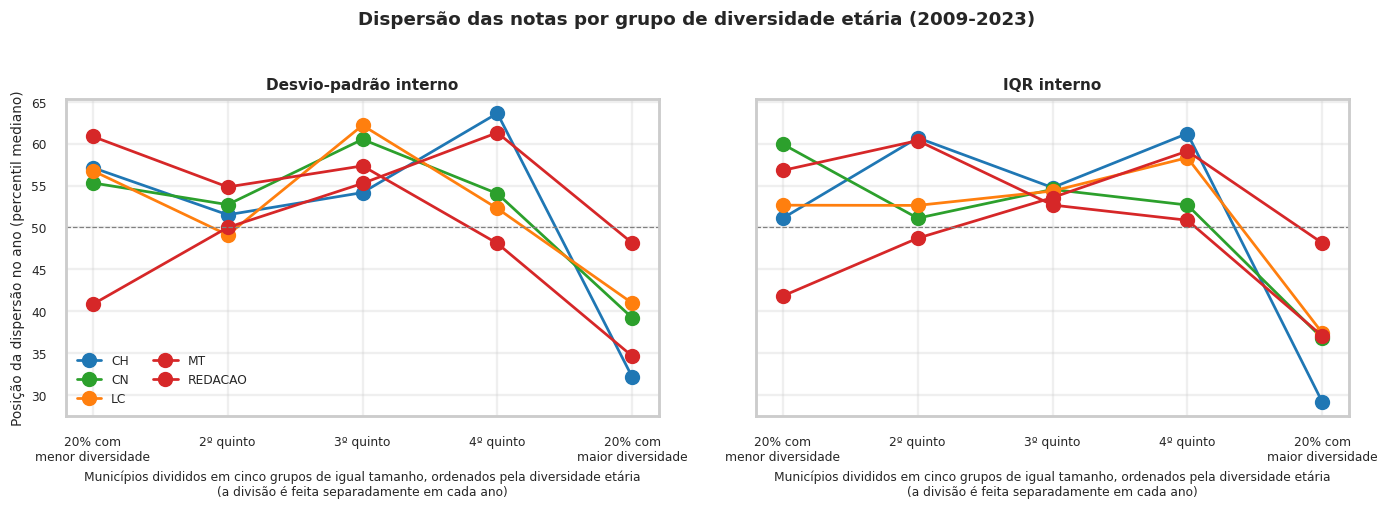

In [39]:
r04_municipal, r04_correlacoes = eda2.analisar_r04_diversidade_etaria_dispersao(faixa, desempenho_e7, TIPO_REFERENCIA)


c = r04_correlacoes[(r04_correlacoes.ano >= 2009) & r04_correlacoes.disciplina.isin(DISC5)].copy()
c["linha"] = c.disciplina + " · " + c.indicador_dispersao.map({"std": "DP", "iqr_interno": "IQR"})
ordem = [f"{d} · {i}" for d in DISC5 for i in ["DP", "IQR"]]
h = c.pivot(index="linha", columns="ano", values="spearman").loc[ordem]

fig, ax = plt.subplots(figsize=(13, 4.6))
sns.heatmap(h, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-.5, vmax=.5,
            annot_kws={"fontsize": 7}, linewidths=.5, linecolor="white",
            cbar_kws={"label": "Spearman (diversidade etária × dispersão)"}, ax=ax)
for y in range(2, 10, 2):
    ax.axhline(y, color="k", lw=1)              # separa as disciplinas
ax.set_title("Diversidade etária (Shannon) e dispersão interna das notas, por ano "
             "(DP = desvio-padrão; IQR = amplitude interquartil)", fontsize=11, fontweight="bold")
ax.set_xlabel(""); ax.set_ylabel("")
ax.tick_params(labelsize=8); ax.figure.axes[-1].tick_params(labelsize=8)
plt.tight_layout(); plt.show()

MIN_N, N_GRUPOS = 200, 5      # MIN_N: notas válidas mínimas (std de município pequeno é instável)

r = r04_municipal[(r04_municipal.ano >= 2009) & r04_municipal.disciplina.isin(DISC5)].copy()
r = r[r.n_validos >= MIN_N].dropna(subset=["shannon_normalizado"])
r["grupo"] = r.groupby("ano").shannon_normalizado.transform(
    lambda v: pd.qcut(v.rank(method="first"), N_GRUPOS, labels=False) + 1)
rot = ["20% com\nmenor diversidade", "2º quinto", "3º quinto", "4º quinto", "20% com\nmaior diversidade"]


fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharex=True, sharey=True)
for ax, (met, nome) in zip(axes, [("std", "Desvio-padrão interno"), ("iqr_interno", "IQR interno")]):
    dd = r.dropna(subset=[met]).copy()
    dd["pos"] = dd.groupby(["ano", "disciplina"])[met].rank(pct=True) * 100
    for disc in DISC5:
        t = dd[dd.disciplina == disc].groupby("grupo").pos.median()
        ax.plot(t.index, t.values, marker="o", lw=1.8, color=CORES[disc], label=disc)
    ax.axhline(50, color="gray", ls="--", lw=.8)
    ax.set_xticks(range(1, N_GRUPOS + 1)); ax.set_xticklabels(rot, fontsize=8)
    ax.set_title(nome, fontsize=10, fontweight="bold")
    ax.set_xlabel("Grupo de diversidade etária (Shannon normalizado, dentro de cada ano)", fontsize=8)
    ax.grid(alpha=.3); ax.tick_params(labelsize=8)
    ax.set_xlabel("Municípios divididos em cinco grupos de igual tamanho, ordenados pela diversidade "
              "etária\n(a divisão é feita separadamente em cada ano)", fontsize=8)
axes[0].set_ylabel("Posição da dispersão no ano (percentil mediano)", fontsize=9)
axes[0].legend(frameon=False, fontsize=8, ncol=2)

fig.suptitle("Dispersão das notas por grupo de diversidade etária (2009-2023)",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


### Comentários
A diversidade etária foi representada pelo índice de Shannon normalizado, calculado a partir da distribuição dos participantes nas faixas etárias. Esse indicador foi relacionado a duas medidas de dispersão das notas dentro de cada município e disciplina: o desvio-padrão (`std`) e o intervalo interquartil (`iqr_interno`). A análise das correlações foi restrita ao período de 2009 a 2023, considerando as mudanças na escala e na estrutura da prova a partir de 2009.

No conjunto completo de dados, foram registradas 194 combinações de ano, disciplina e indicador de dispersão, das quais 190 apresentaram correlações válidas. No recorte de 2009 a 2023, utilizado na análise principal, todas as 150 combinações apresentaram coeficientes válidos. As correlações de Spearman mostram magnitudes predominantemente pequenas e variáveis ao longo do tempo. Considerando as médias dos coeficientes no período, os valores variam de −0,059 a 0,117, conforme a disciplina e a medida de dispersão. Redação apresenta as maiores médias positivas, tanto para o desvio-padrão (0,093) quanto para o IQR (0,117). Em Linguagens, a média do IQR também é positiva (0,066), enquanto as demais combinações apresentam valores próximos de zero ou ligeiramente negativos.

Em 2023, os coeficientes foram:

| Ano  | Disciplina | Dispersão   | Municípios | Pearson | Spearman |
| ---- | ---------- | ----------- | ---------- | ------- | -------- |
| 2023 | CH         | std         | 139        | 0,088   | 0,033    |
| 2023 | CH         | iqr_interno | 141        | 0,113   | 0,022    |
| 2023 | CN         | std         | 139        | 0,084   | 0,003    |
| 2023 | CN         | iqr_interno | 141        | 0,141   | 0,098    |
| 2023 | LC         | std         | 139        | 0,125   | 0,070    |
| 2023 | LC         | iqr_interno | 141        | 0,236   | 0,171    |
| 2023 | MT         | std         | 139        | −0,040  | −0,084   |
| 2023 | MT         | iqr_interno | 141        | 0,058   | 0,030    |
| 2023 | Redação    | std         | 139        | 0,117   | 0,103    |
| 2023 | Redação    | iqr_interno | 141        | 0,221   | 0,162    |

Os resultados de 2023 mostram associações positivas na maior parte das combinações, mas de pequena magnitude. As maiores correlações ocorrem em Linguagens e Redação, especialmente quando a dispersão é medida pelo IQR. Em Matemática, a correlação com o desvio-padrão é negativa, enquanto a associação com o IQR é próxima de zero. Portanto, não há um comportamento uniforme entre as disciplinas ou entre as medidas de dispersão.

A segunda abordagem complementa essa análise por meio da comparação entre cinco grupos de diversidade etária, formados separadamente em cada ano. Foram considerados municípios com pelo menos 200 notas válidas por disciplina, sendo o G1 composto pelos municípios de menor diversidade e o G5 pelos de maior diversidade. A dispersão foi comparada por sua posição percentual na distribuição anual de cada disciplina e também pelos valores medianos do desvio-padrão e do IQR.

Nas quatro provas objetivas, os municípios do G5 apresentam posições medianas de dispersão inferiores às observadas no G1. Para o desvio-padrão, a posição mediana passa de 57,14 para 32,14 em CH, de 55,32 para 39,21 em CN, de 56,78 para 40,97 em LC e de 60,87 para 34,63 em MT. O mesmo comportamento aparece no IQR: no G1, as posições medianas variam de 51,11 a 59,95, enquanto no G5 ficam entre 29,17 e 37,41.

Os valores absolutos medianos também são menores no grupo de maior diversidade. Para o desvio-padrão, o G5 apresenta 70,21 em CH, 60,38 em CN, 64,62 em LC e 77,74 em MT, abaixo dos respectivos valores do G1: 72,63, 63,57, 66,37 e 83,62. Para o IQR, a mesma diferença é observada em todas as provas objetivas: 97,65 contra 102,48 em CH; 84,00 contra 89,91 em CN; 89,31 contra 91,59 em LC; e 106,69 contra 110,98 em MT.

Em Redação, a relação é menos consistente. A posição mediana do desvio-padrão aumenta do G1 (40,83) ao G4 (61,32), mas recua no G5 (48,15). Para o IQR, a posição mediana também cresce até o G4 (59,12) e diminui no G5 (48,15). Os valores absolutos não mostram uma redução equivalente à observada nas provas objetivas: o desvio-padrão mediano passa de 213,08 no G1 para 215,76 no G5, enquanto o IQR passa de 225,00 para 240,00. Assim, não se observa em Redação o mesmo padrão de menor dispersão nos municípios de maior diversidade etária.

Outro aspecto relevante é a evolução da diversidade etária ao longo do período. A mediana anual do índice de Shannon normalizado diminui de 0,677 em 2009 para 0,281 em 2023. Essa redução indica uma mudança na distribuição dos participantes entre as faixas etárias nos municípios analisados e constitui um contexto importante para interpretar os resultados, embora não estabeleça, isoladamente, uma relação com a dispersão das notas.

A correlações anuais indicam que a associação entre diversidade etária e dispersão das notas é geralmente fraca e varia conforme o ano, a disciplina e o indicador utilizado. Entretanto, a comparação por grupos revela um padrão mais definido nas quatro provas objetivas: municípios classificados entre os de maior diversidade etária tendem a apresentar menor dispersão interna das notas, tanto pelo desvio-padrão quanto pelo IQR. Em Redação, esse comportamento não se reproduz de maneira consistente. Portanto, os resultados sugerem uma associação entre diversidade etária e dispersão que depende da área avaliada, sem permitir concluir que a diversidade etária, isoladamente, determine a variabilidade do desempenho municipal.


## 5. Gap entre redes e desigualdade territorial

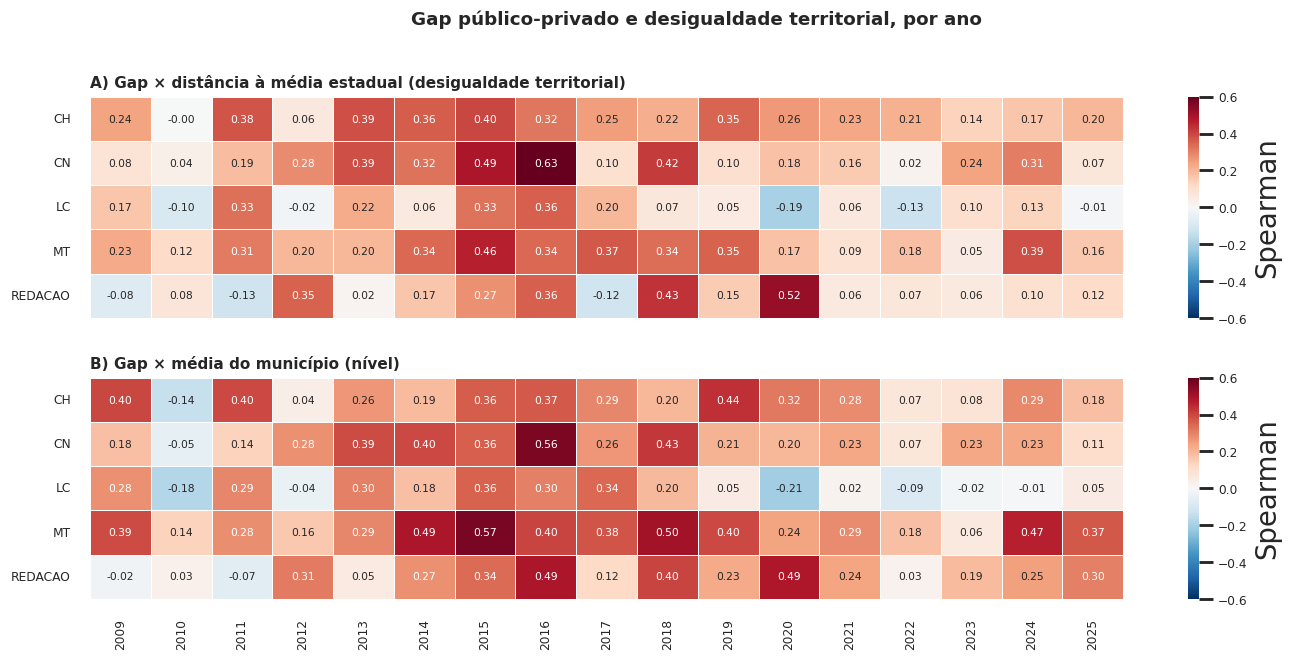

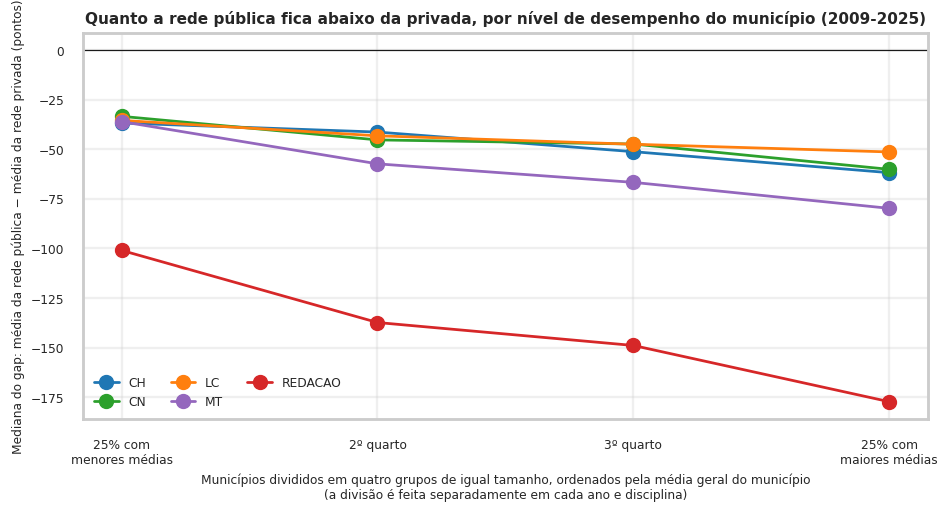

In [7]:
r05_municipal, r05_correlacoes = eda2.analisar_r05_gap_redes_desigualdade(painel, grupo, desempenho_e7, TIPO_REFERENCIA)

c = r05_correlacoes[(r05_correlacoes.ano >= 2009) & r05_correlacoes.disciplina.isin(DISC5)]
paineis = [("spearman_gap_abs_desvio", "A) Gap × distância à média estadual (desigualdade territorial)"),
           ("spearman_gap_abs_media",  "B) Gap × média do município (nível)")]

fig, axes = plt.subplots(2, 1, figsize=(13, 6.2), sharex=True)
for ax, (col, titulo) in zip(axes, paineis):
    h = c.pivot(index="disciplina", columns="ano", values=col).loc[DISC5]
    sns.heatmap(h, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-.6, vmax=.6,
                annot_kws={"fontsize": 7}, linewidths=.5, linecolor="white",
                cbar_kws={"label": "Spearman"}, ax=ax)
    ax.set_title(titulo, fontsize=10, fontweight="bold", loc="left")
    ax.set_xlabel(""); ax.set_ylabel("")
    ax.tick_params(labelsize=8); ax.figure.axes[-1].tick_params(labelsize=8)
fig.suptitle("Gap público-privado e desigualdade territorial, por ano", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()


N_GRUPOS = 4
r = (r05_municipal[(r05_municipal.ano >= 2009) & r05_municipal.disciplina.isin(DISC5)]
     .dropna(subset=["gap_publica_menos_privada", "media_municipal"]).copy())
r["grupo"] = r.groupby(["ano", "disciplina"]).media_municipal.transform(
    lambda v: pd.qcut(v.rank(method="first"), N_GRUPOS, labels=False) + 1)
t = (r.groupby(["disciplina", "grupo"]).gap_publica_menos_privada
       .agg(mediana="median", n="size").reset_index())

rotulos = ["25% com\nmenores médias", "2º quarto", "3º quarto", "25% com\nmaiores médias"]

fig, ax = plt.subplots(figsize=(9, 5))
for disc in DISC5:
    s = t[t.disciplina == disc]
    ax.plot(s.grupo, s.mediana, marker="o", lw=1.8, color=CORES[disc], label=disc)
ax.axhline(0, color="k", lw=.8)
ax.set_xticks(range(1, N_GRUPOS + 1))
ax.set_xticklabels(rotulos, fontsize=8)
ax.set_xlabel("Municípios divididos em quatro grupos de igual tamanho, ordenados pela média "
              "geral do município\n(a divisão é feita separadamente em cada ano e disciplina)",
              fontsize=8)
ax.set_ylabel("Mediana do gap: média da rede pública − média da rede privada (pontos)", fontsize=8)
ax.set_title("Quanto a rede pública fica abaixo da privada, por nível de desempenho do município (2009-2025)",
             fontsize=10, fontweight="bold")
ax.legend(frameon=False, fontsize=8, ncol=3); ax.grid(alpha=.3); ax.tick_params(labelsize=8)
plt.tight_layout(); plt.show()

### Comentários
A análise relaciona a diferença de desempenho entre as redes pública e privada à posição dos municípios na distribuição territorial das médias do ENEM. O gap foi calculado pela diferença entre a média da rede pública e a da rede privada, considerando médias ponderadas pelo número de participantes válidos. Valores negativos indicam desempenho médio inferior da rede pública. Para investigar sua relação com a desigualdade territorial, foi utilizado o gap absoluto, comparado tanto à distância absoluta da média municipal em relação à média dos municípios quanto ao próprio nível de desempenho municipal.

Foram considerados apenas municípios com resultados nas duas redes, o que restringe a análise a aproximadamente 35–54 municípios por ano e disciplina. O período de 2009 a 2025 foi adotado para manter a comparabilidade das escalas e provas do ENEM. Nesse intervalo, foram avaliados 85 recortes anuais por disciplina, considerando as cinco áreas do exame.

As correlações de Spearman indicam que as associações são, em média, positivas, mas apresentam intensidade variável entre as disciplinas. A relação entre o gap absoluto e a distância em relação à média territorial é mais evidente em Matemática, Ciências Humanas e Ciências da Natureza. Já a associação com a média municipal também se destaca em Matemática, enquanto Linguagens apresenta os menores coeficientes médios nos dois casos.

| Disciplina           | Gap × distância territorial | Gap × média municipal |
| -------------------- | --------------------------- | --------------------- |
| Ciências Humanas     | 0,246                       | 0,237                 |
| Ciências da Natureza | 0,236                       | 0,249                 |
| Linguagens           | 0,096                       | 0,108                 |
| Matemática           | 0,253                       | 0,329                 |
| Redação              | 0,143                       | 0,214                 |


A variação anual reforça que essas relações não são constantes. Há recortes com associações moderadas, como Ciências da Natureza em 2016, cuja correlação de Spearman entre o gap absoluto e a distância territorial foi de 0,632, e Redação em 2020, com coeficiente de 0,522 para essa mesma relação. Em contrapartida, Linguagens apresenta correlações próximas de zero ou negativas em alguns anos. Portanto, os resultados não indicam um comportamento uniforme entre as disciplinas ou ao longo do período.

A análise por grupos de desempenho municipal acrescenta outra perspectiva. Os municípios foram distribuídos em quatro grupos de médias, definidos separadamente para cada ano e disciplina: G1 reúne os 25% com menores médias e G4 os 25% com maiores médias. Em todas as disciplinas, a mediana do gap público-privado é negativa nos quatro grupos e se torna progressivamente mais negativa de G1 a G4. Esse comportamento também é acompanhado pelo aumento do gap absoluto mediano, indicando que a diferença entre as redes tende a ser maior nos grupos de municípios com médias mais elevadas.

Esse padrão é particularmente expressivo em Matemática: o gap mediano passa de -36,05 pontos em G1 para -79,76 pontos em G4. Em Redação, a diferença também é acentuada, passando de -100,96 para -177,27 pontos. Esses resultados mostram que a desigualdade entre as redes não se distribui de maneira homogênea entre os grupos de desempenho municipal.

Os resultados apontam para uma associação entre a magnitude da diferença de desempenho das redes pública e privada e o nível de desempenho dos municípios, especialmente em Matemática. Também há associação positiva, embora variável, entre o gap e a distância territorial em determinadas disciplinas e anos. Entretanto, essa relação não é uniforme: os coeficientes variam entre disciplinas e períodos, e há recortes com associações fracas ou negativas. Assim, os resultados sugerem que a desigualdade entre as redes pode acompanhar aspectos da desigualdade territorial, mas não permitem afirmar que ambas caminham necessariamente juntas ou estabelecer uma relação causal.


## 6. Síntese dos resultados


As cinco análises mostram que as relações entre participação, composição dos participantes e desempenho municipal no ENEM não seguem um padrão único. Algumas associações se mantêm ao longo dos anos ou entre disciplinas, enquanto outras variam conforme o período e o indicador utilizado. Portanto, nenhuma das dimensões investigadas explica, isoladamente, as diferenças de desempenho entre os municípios paraenses.

**Crescimento da participação e desempenho**

Entre 2009 e 2025, o crescimento da participação no ENEM não foi acompanhado, de maneira geral, pelo aumento das médias municipais. As correlações entre essas variáveis foram predominantemente fracas, embora Matemática tenha apresentado uma associação negativa mais expressiva. A comparação entre os grupos de municípios com diferentes taxas de crescimento da participação também não revelou uma evolução progressiva do desempenho. Assim, municípios que ampliaram mais o número de participantes não necessariamente apresentaram maiores aumentos nas médias.

**Participação da rede pública e desempenho**

A proporção de participantes da rede pública apresentou a associação mais consistente com o desempenho municipal. Entre 2009 e 2025, as correlações foram negativas nas cinco disciplinas: municípios com maior participação relativa da rede pública tenderam a apresentar menores médias gerais.

Esse resultado, entretanto, precisa ser interpretado considerando a forma de cálculo do indicador. A média municipal reúne as notas de participantes de todas as dependências administrativas. Portanto, a associação observada representa uma relação entre a composição da participação e o desempenho no território, e não uma comparação direta entre o desempenho individual de estudantes das redes pública e privada.

**Composição por sexo e desempenho**

A composição por sexo não apresentou uma relação consistente com as médias municipais. As correlações anuais foram geralmente fracas e alternaram de sinal. Da mesma forma, a comparação das mudanças entre 2009 e 2023 resultou em coeficientes de Spearman próximos de zero.

Embora a participação feminina tenha apresentado redução mediana no período, enquanto as médias municipais aumentaram nas cinco disciplinas, essas mudanças simultâneas não indicam uma associação sistemática entre a composição por sexo e a evolução do desempenho.

**Diversidade etária e dispersão das notas**

A relação entre diversidade etária e dispersão das notas também variou conforme o indicador utilizado. As correlações anuais foram predominantemente fracas e apresentaram sinais diferentes ao longo do período.

Na comparação entre grupos de municípios, porém, apareceu um padrão mais definido nas quatro provas objetivas: aqueles classificados entre os de maior diversidade etária apresentaram, em geral, menor dispersão das notas. Em Redação, esse comportamento não foi observado de forma consistente. Portanto, a relação entre diversidade etária e variabilidade do desempenho depende da disciplina e da abordagem de análise.

**Desigualdade entre redes e diferenças territoriais**

A diferença de desempenho entre as redes pública e privada variou conforme o desempenho dos municípios. O gap foi desfavorável à rede pública em todos os grupos e aumentou progressivamente dos municípios com menores médias para aqueles com maiores médias. Esse comportamento foi especialmente expressivo em Matemática e Redação.

As correlações entre o gap de desempenho e a distância territorial foram predominantemente positivas em algumas disciplinas, mas variaram entre os anos e as áreas avaliadas. Isso indica que as diferenças entre as redes acompanham parcialmente as desigualdades territoriais, mas essa relação não é uniforme.

 <div style="background-color: #E2E8F0; padding: 12px; border-radius: 6px;">
    
**Síntese Final**  
 Entre as dimensões investigadas, a participação relativa da rede pública apresentou a associação mais persistente com as médias municipais. A expansão da participação no exame e as mudanças na composição por sexo, por outro lado, não mostraram correspondência sistemática com a evolução do desempenho. A diversidade etária apresentou uma associação com menor dispersão nas provas objetivas, mas não em Redação. Já a desigualdade entre as redes pública e privada foi maior nos grupos de municípios com médias mais elevadas, embora sua relação com as diferenças territoriais tenha variado entre disciplinas e anos. Em conjunto, os resultados mostram que as relações entre participação, perfil dos participantes e desempenho municipal dependem da dimensão analisada. Não há um único padrão capaz de explicar as diferenças de desempenho entre os municípios do Pará.
</div>